# Run Scrublet pipeline

In [27]:
# Load libraries
%matplotlib inline
import scrublet as scr
import scipy.io
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import os
import h5py
import scipy.sparse as sp
import scanpy as sc

In [2]:
%matplotlib inline

In [3]:
import pandas as pd

In [4]:
plt.rc('font', size=14)
plt.rcParams['pdf.fonttype'] = 42

#### Load counts matrix and gene list
Load the raw counts matrix as a scanpy sparse matrix with cells as rows and genes as columns.

In [32]:
os.getcwd()
os.path.isfile("../results/01_remove_ambient_RNA/10dpci_veh_filtered.h5")
adata = scanpy.read_h5ad("../results/CB2Scrublet/counts_matrix.h5ad")

In [ ]:
cells = adata.obs_names # Cells
genes = adata.var_names # Genes

In [42]:
# Filter dataset (same as Seurat pipeline)
import numpy as np
import scanpy as sc

adata = sc.read_h5ad("../results/CB2Scrublet/counts_matrix.h5ad")

# --- Compute QC metrics on the full matrix ---
cell_sums = np.array(adata.X.sum(axis=1)).ravel()        # nCount_RNA
cell_nnz  = np.array((adata.X > 0).sum(axis=1)).ravel()  # nFeature_RNA
gene_nnz  = np.array((adata.X > 0).sum(axis=0)).ravel()  # cells per gene

# --- Build masks without sequential filtering ---
cell_mask = (cell_sums < 50000) & (cell_nnz > 200)
gene_mask = gene_nnz >= 3

# --- Apply both masks at once ---
adata = adata[cell_mask, :][:, gene_mask]

adata

View of AnnData object with n_obs × n_vars = 16737 × 23088
    obs: 'background_fraction', 'cell_probability', 'cell_size', 'droplet_efficiency', 'n_cellranger', 'n_cellbender'
    var: 'ambient_expression', 'feature_type', 'genome', 'gene_id', 'cellbender_analyzed', 'n_cellranger', 'n_cellbender'
    uns: 'cell_size_lognormal_std', 'empty_droplet_size_lognormal_loc', 'empty_droplet_size_lognormal_scale', 'estimator', 'features_analyzed_inds', 'fraction_data_used_for_testing', 'learning_curve_learning_rate_epoch', 'learning_curve_learning_rate_value', 'learning_curve_test_elbo', 'learning_curve_test_epoch', 'learning_curve_train_elbo', 'learning_curve_train_epoch', 'swapping_fraction_dist_params', 'target_false_positive_rate'
    obsm: 'cellbender_embedding'
    layers: 'cellbender', 'cellranger'

In [43]:
counts_matrix = adata.layers["cellbender"]
counts_matrix

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 54996020 stored elements and shape (16737, 23088)>

In [44]:
preview = counts_matrix[:5, :10].toarray()
print(preview)


[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0]
 [0 2 0 1 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0 0 0]]


#### Initialize Scrublet object
The relevant parameters are:
- *expected_doublet_rate*: the expected fraction of transcriptomes that are doublets, typically 0.05-0.1. Results are not particularly sensitive to this parameter. For this example, the expected doublet rate comes from the Chromium User Guide: https://support.10xgenomics.com/permalink/3vzDu3zQjY0o2AqkkkI4CC
- *sim_doublet_ratio*: the number of doublets to simulate, relative to the number of observed transcriptomes. This should be high enough that all doublet states are well-represented by simulated doublets. Setting it too high is computationally expensive. The default value is 2, though values as low as 0.5 give very similar results for the datasets that have been tested.
- *n_neighbors*: Number of neighbors used to construct the KNN classifier of observed transcriptomes and simulated doublets. The default value of `round(0.5*sqrt(n_cells))` generally works well.


In [46]:
scrub = scr.Scrublet(counts_matrix, expected_doublet_rate=0.08)

# Doublet simulation
1. Doublet simulation
2. Normalization, gene filtering, rescaling, PCA
3. Doublet score calculation 
4. Doublet score threshold detection and doublet calling


In [47]:
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, 
                                                          min_cells=3, 
                                                          min_gene_variability_pctl=85, 
                                                          n_prin_comps=30)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.28
Detected doublet rate = 3.5%
Estimated detectable doublet fraction = 43.0%
Overall doublet rate:
	Expected   = 8.0%
	Estimated  = 8.2%
Elapsed time: 38.3 seconds


In [48]:
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, 
                                                          min_cells=3, 
                                                          min_gene_variability_pctl=85, 
                                                          n_prin_comps=30)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.31
Detected doublet rate = 2.7%
Estimated detectable doublet fraction = 32.0%
Overall doublet rate:
	Expected   = 8.0%
	Estimated  = 8.6%
Elapsed time: 9.7 seconds


#### Plot doublet score histograms  for observed transcriptomes and simulated doublets
The simulated doublet histogram is typically bimodal. The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression. The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses. Scrublet can only detect neotypic doublets.  
  
To call doublets vs. singlets, we must set a threshold doublet score, ideally at the minimum between the two modes of the simulated doublet histogram. `scrub_doublets()` attempts to identify this point automatically and has done a good job in this example. However, if automatic threshold detection doesn't work well, you can adjust the threshold with the `call_doublets()` function. For example:
```python
scrub.call_doublets(threshold=0.25)
```

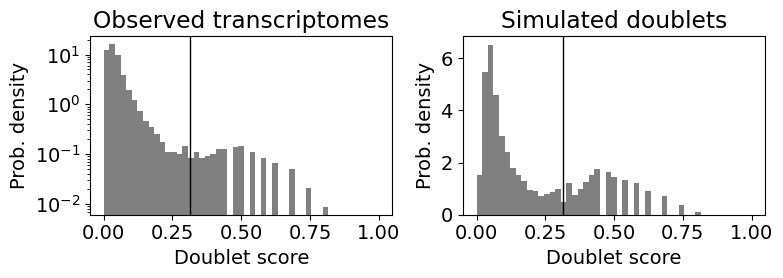

In [49]:
scrub.plot_histogram();

#### Get 2-D embedding to visualize the results

In [50]:
print('Running UMAP...')
scrub.set_embedding('UMAP', scr.get_umap(scrub.manifold_obs_, 10, min_dist=0.3))

# # Uncomment to run tSNE - slow
# print('Running tSNE...')
# scrub.set_embedding('tSNE', scr.get_tsne(scrub.manifold_obs_, angle=0.9))

# # Uncomment to run force layout - slow
# print('Running ForceAtlas2...')
# scrub.set_embedding('FA', scr.get_force_layout(scrub.manifold_obs_, n_neighbors=5. n_iter=1000))
    
print('Done.')

Running UMAP...


/root/miniforge3/envs/scrublet_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/root/miniforge3/envs/scrublet_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Done.


In [51]:
print(scrub.overall_doublet_rate_)
print(scrub.detected_doublet_rate_)

0.08587697190329506
0.027484017446376293


#### Plot doublet predictions on 2-D embedding
Predicted doublets should co-localize in distinct states.

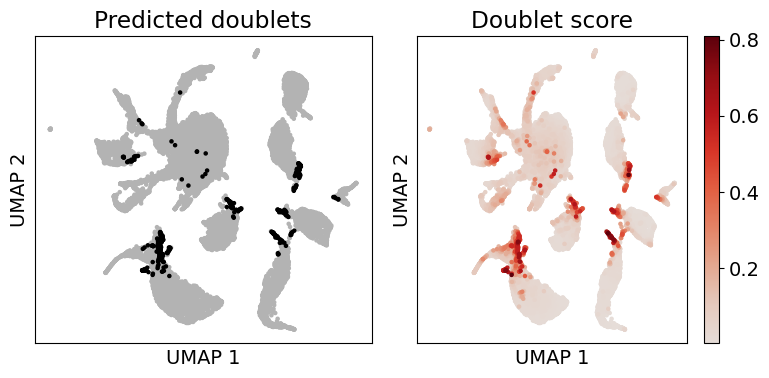

In [52]:
scrub.plot_embedding('UMAP', order_points=True);

# scrub.plot_embedding('tSNE', order_points=True);
# scrub.plot_embedding('FA', order_points=True);

In [53]:
# Store results in AnnData
adata.obs["doublet_score"] = doublet_scores
adata.obs["predicted_doublet"] = predicted_doublets

/tmp/ipykernel_2754/1749762571.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["doublet_score"] = doublet_scores


In [54]:
adata

AnnData object with n_obs × n_vars = 16737 × 23088
    obs: 'background_fraction', 'cell_probability', 'cell_size', 'droplet_efficiency', 'n_cellranger', 'n_cellbender', 'doublet_score', 'predicted_doublet'
    var: 'ambient_expression', 'feature_type', 'genome', 'gene_id', 'cellbender_analyzed', 'n_cellranger', 'n_cellbender'
    uns: 'cell_size_lognormal_std', 'empty_droplet_size_lognormal_loc', 'empty_droplet_size_lognormal_scale', 'estimator', 'features_analyzed_inds', 'fraction_data_used_for_testing', 'learning_curve_learning_rate_epoch', 'learning_curve_learning_rate_value', 'learning_curve_test_elbo', 'learning_curve_test_epoch', 'learning_curve_train_elbo', 'learning_curve_train_epoch', 'swapping_fraction_dist_params', 'target_false_positive_rate'
    obsm: 'cellbender_embedding'
    layers: 'cellbender', 'cellranger'

In [55]:
adata.write("../results/CB2Scrublet/scrubbed_counts_matrix.h5ad")

In [55]:
results = pd.Series(scrub.predicted_doublets_, name="scrublet_DropletType")
results

0        False
1        False
2        False
3        False
4        False
         ...  
32727    False
32728    False
32729    False
32730    False
32731    False
Name: scrublet_DropletType, Length: 32732, dtype: bool

In [56]:
scores = pd.Series(scrub.doublet_scores_obs_, name="scrublet_Scores")
scores

0        0.152408
1        0.193133
2        0.099419
3        0.109608
4        0.105350
           ...   
32727    0.000118
32728    0.000118
32729    0.000118
32730    0.000118
32731    0.000118
Name: scrublet_Scores, Length: 32732, dtype: float64

In [69]:
cells = adata.obs_names # Cells
barcodes = pd.DataFrame(adata.obs_names.to_list(), columns=["barcode"])
barcodes

,barcode
0,TATACGTAGCGGTTCG-1
1,CCCTCACAGTCATTGG-1
2,TGCATAACACTACCAC-1
3,GTCCTGCTCCAGCAAC-1
4,TGCTTAAGTTGCTCGA-1
...,...
32727,GCATTCAAGCTATGGC-1
32728,GTGCATTGTAACTGCT-1
32729,GCCCATAGTTTGGCTG-1
32730,TCACCCGCACCATTCA-1


In [70]:

dataframe = pd.concat([barcodes, results, scores], axis=1)
dataframe.scrublet_DropletType = dataframe.scrublet_DropletType.replace(True, "doublet")
dataframe.scrublet_DropletType = dataframe.scrublet_DropletType.replace(False, "singlet")
dataframe.to_csv('../results/CB2Scrublet/scrublet_results.tsv', sep = "\t", index = False)
dataframe.to_csv('../results/CB2Scrublet/scrublet_results.csv', sep = ";", index = False)